In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

from smartmeter.db import get_engine
connection = get_engine()


# Opdracht 1

### Deel 1


```sql
USE DigitalMeterDWH
GO

ALTER TABLE DimUser ADD UserType nvarchar(100) NULL
GO

UPDATE DimUser
SET UserType = CASE
    WHEN PVInstallationIndicator = '1' AND HeatPumpIndicator = '0' AND ElectricVehicleIndicator = '0' THEN 'Met zonnepanelen'
    WHEN PVInstallationIndicator = '0' AND ElectricVehicleIndicator = '0' THEN 'Zonder zonnepanelen'
    WHEN PVInstallationIndicator = '1' AND HeatPumpIndicator = '1' THEN 'Met warmtepomp en met zonnepanelen'
    WHEN PVInstallationIndicator = '1' AND ElectricVehicleIndicator = '1' THEN 'Met zonnepanelen en een thuisopladend elektrisch voertuig'
    WHEN PVInstallationIndicator = '0' AND ElectricVehicleIndicator = '1' THEN 'Zonder zonnepanelen en met een thuisopladend elektrisch voertuig'
END
GO
```


In [2]:
dimUser = pd.read_sql('SELECT UserType, COUNT(UserKey) AS "NumberOfUsers" FROM DimUser GROUP BY UserType', connection)
dimUser.head()


,UserType,NumberOfUsers
0,Met zonnepanelen,300
1,Met warmtepomp en met zonnepanelen,600
2,Met zonnepanelen en een thuisopladend elektris...,300
3,Zonder zonnepanelen,600
4,Zonder zonnepanelen en met een thuisopladend e...,600


### Deel 2


```sql
USE DigitalMeterDWH
GO

SELECT UserKey, Year, Month,
	MIN(dd.DateKey) AS 'StartDateKey', MIN(FullDateAlternateKey) AS 'StartDate',
	SUM(Usage_kWh) AS 'MonthlyUsage_kWh', SUM(Injection_kWh) AS 'MonthlyInjection_kWh',
	MIN(MonthlyPeak_kW) AS 'MonthlyPeak_kW',
	SUM(CASE
		WHEN DaytimeRate = 1 THEN Usage_kWh
		ELSE 0
	END) AS 'MonthlyUsageDay_kWh',
	SUM(CASE
		WHEN DaytimeRate = 1 THEN Injection_kWh
		ELSE 0
	END) AS 'MonthlyInjectionDay_kWh',
	SUM(CASE
		WHEN DaytimeRate = 0 THEN Usage_kWh
		ELSE 0
	END) AS 'MonthlyUsageNight_kWh',
	SUM(CASE
		WHEN DaytimeRate = 0 THEN Injection_kWh
		ELSE 0
	END) AS 'MonthlyInjectionNight_kWh'
INTO FactEnergyUsageMonthly
FROM FactEnergyUsage feu
JOIN DimDate dd ON feu.DateKey = dd.DateKey
GROUP BY feu.UserKey, dd.Year, dd.Month
ORDER BY feu.UserKey, dd.Year, CAST(dd.Month AS int)
GO

ALTER TABLE FactEnergyUsageMonthly ADD CONSTRAINT FK_FactEnergyUsageMonthly_DimDate FOREIGN KEY (StartDateKey) REFERENCES DimDate (DateKey)
ALTER TABLE FactEnergyUsageMonthly ADD CONSTRAINT FK_FactEnergyUsageMonthly_DimUser FOREIGN KEY (UserKey) REFERENCES DimUser (UserKey)
GO
```


In [3]:
factEnergyUsageMonthly = pd.read_sql('SELECT * FROM FactEnergyUsageMonthly ORDER BY UserKey, Year, CAST(Month AS int)', connection)
factEnergyUsageMonthly.head()


,UserKey,Year,Month,StartDateKey,StartDate,MonthlyUsage_kWh,MonthlyInjection_kWh,MonthlyPeak_kW,MonthlyUsageDay_kWh,MonthlyInjectionDay_kWh,MonthlyUsageNight_kWh,MonthlyInjectionNight_kWh
0,1,2024,1,20240101,2024-01-01,335.972,57.580,5.192,186.803,45.058,149.169,12.522
1,1,2024,2,20240201,2024-02-01,298.048,71.632,5.636,136.488,55.435,161.560,16.197
2,1,2024,3,20240301,2024-03-01,229.387,222.514,5.352,95.474,160.763,133.913,61.751
3,1,2024,4,20240401,2024-04-01,214.754,378.477,4.204,82.058,279.241,132.696,99.236
4,1,2024,5,20240501,2024-05-01,168.756,436.406,4.000,58.216,316.872,110.540,119.534


# Opdracht 2


We halen de data van gebruiker 60 op. We gebruiken enkel de kolommen `Month` en `MonthlyInjection_kWh`.


In [4]:
injectionMonthlyUser60 = pd.read_sql('SELECT Month, MonthlyInjection_kWh FROM FactEnergyUsageMonthly WHERE UserKey = 60', connection)
injectionMonthlyUser60.head()


,Month,MonthlyInjection_kWh
0,3,146.397
1,11,22.045
2,6,387.263
3,2,36.128
4,8,392.931


We halen de belpex prijs op van het jaar 2024. We halen enkel de kolommen `Month` en `BelpexPrice`. We groeperen de rijen per maand en gebruiken de gemiddelde belpex prijs.


In [5]:
avgBelpexMonthly2024 = pd.read_sql('SELECT Month, AVG(BelpexPrice) AS "AvgBelpexPrice" FROM FactBelpex fb JOIN DimDate dd ON fb.DateKey = dd.DateKey WHERE Year = 2024 GROUP BY Month', connection)
avgBelpexMonthly2024.head()


,Month,AvgBelpexPrice
0,1,78.560094
1,10,77.897217
2,11,108.941958
3,12,105.222016
4,2,61.515373


We halen de injectie-factoren en balanceringskosten op van het jaar 2024 van het contract Octa+ Eco Clear. We halen enkel de kolom `Month` op samen met alle injectie-factoren en balanceringskosten.


In [6]:
energyCostOctaPlusSmartVariabel2024 = pd.read_sql('SELECT Month, SingleMeterInjectionMeterFactor, SingleMeterInjectionBalancingCost, DualMeterDayInjectionMeterFactor, DualMeterDayInjectionBalancingCost, DualMeterNightInjectionMeterFactor, DualMeterNightInjectionBalancingCost FROM FactEnergyCost fec JOIN DimDate dd ON fec.DateKey = dd.DateKey JOIN DimContract dc ON fec.ContractKey = dc.ContractKey WHERE ContractName = \'OCTA+ Eco Clear\' AND Year = 2024', connection)
energyCostOctaPlusSmartVariabel2024.head()


,Month,SingleMeterInjectionMeterFactor,SingleMeterInjectionBalancingCost,DualMeterDayInjectionMeterFactor,DualMeterDayInjectionBalancingCost,DualMeterNightInjectionMeterFactor,DualMeterNightInjectionBalancingCost
0,1,0.915,-19.83,0.915,-19.83,0.915,-19.83
1,2,0.915,-19.83,0.915,-19.83,0.915,-19.83
2,3,0.915,-19.83,0.915,-19.83,0.915,-19.83
3,4,0.915,-19.83,0.915,-19.83,0.915,-19.83
4,5,0.915,-19.83,0.915,-19.83,0.915,-19.83


We hangen nu die 3 tabellen aan elkaar op basis van de overeenkomende maand.


In [7]:
injectionMonthlyUser60 = injectionMonthlyUser60.merge(avgBelpexMonthly2024, on='Month', how='left')
injectionMonthlyUser60 = injectionMonthlyUser60.merge(energyCostOctaPlusSmartVariabel2024, on='Month', how='left')
injectionMonthlyUser60.head()


,Month,MonthlyInjection_kWh,AvgBelpexPrice,SingleMeterInjectionMeterFactor,SingleMeterInjectionBalancingCost,DualMeterDayInjectionMeterFactor,DualMeterDayInjectionBalancingCost,DualMeterNightInjectionMeterFactor,DualMeterNightInjectionBalancingCost
0,3,146.397,61.169246,0.915,-19.83,0.915,-19.83,0.915,-19.83
1,11,22.045,108.941958,0.915,-19.83,0.915,-19.83,0.915,-19.83
2,6,387.263,60.854527,0.915,-19.83,0.915,-19.83,0.915,-19.83
3,2,36.128,61.515373,0.915,-19.83,0.915,-19.83,0.915,-19.83
4,8,392.931,65.533534,0.915,-19.83,0.915,-19.83,0.915,-19.83


We berekenen per meter hoeveel cent per kWh er wordt verdiend per maand door injectie. We vermenigvuldigen de gemiddelde belpex prijs van een maand met de injectie-factoren en voegen daarbij de balanceringskosten toe. Dan komen we uit op €/MWh. We vermenigvuldigen met 100 om naar cent/MWh te gaan. Dan delen we door 1000 om naar cent/kWh te gaan.


In [8]:
injectionMonthlyUser60['MonthlySingleMeterInjectionProfitCentPerkWh'] = injectionMonthlyUser60['AvgBelpexPrice'] * injectionMonthlyUser60['SingleMeterInjectionMeterFactor'] + injectionMonthlyUser60['SingleMeterInjectionBalancingCost']
injectionMonthlyUser60['MonthlyDualMeterDayInjectionProfitCentPerkWh'] = injectionMonthlyUser60['AvgBelpexPrice'] * injectionMonthlyUser60['DualMeterDayInjectionMeterFactor'] + injectionMonthlyUser60['DualMeterDayInjectionBalancingCost']
injectionMonthlyUser60['MonthlyDualMeterNightInjectionProfitCentPerkWh'] = injectionMonthlyUser60['AvgBelpexPrice'] * injectionMonthlyUser60['DualMeterNightInjectionMeterFactor'] + injectionMonthlyUser60['DualMeterNightInjectionBalancingCost']
injectionMonthlyUser60.drop(columns=['AvgBelpexPrice', 'SingleMeterInjectionMeterFactor', 'SingleMeterInjectionBalancingCost', 'DualMeterDayInjectionMeterFactor', 'DualMeterDayInjectionBalancingCost', 'DualMeterNightInjectionMeterFactor', 'DualMeterNightInjectionBalancingCost'], inplace=True)
injectionMonthlyUser60


,Month,MonthlyInjection_kWh,MonthlySingleMeterInjectionProfitCentPerkWh,MonthlyDualMeterDayInjectionProfitCentPerkWh,MonthlyDualMeterNightInjectionProfitCentPerkWh
0,3,146.397,36.139860,36.139860,36.139860
1,11,22.045,79.851892,79.851892,79.851892
2,6,387.263,35.851892,35.851892,35.851892
3,2,36.128,36.456566,36.456566,36.456566
4,8,392.931,40.133184,40.133184,40.133184
5,4,173.757,24.101438,24.101438,24.101438
6,9,238.104,41.155156,41.155156,41.155156
7,1,54.834,52.052486,52.052486,52.052486
8,5,317.977,29.988380,29.988380,29.988380
9,12,2.238,76.448145,76.448145,76.448145


We berekenen de totale opbrengst per maand door de injectie per maand te vermenigvuldigen met de opbrengst per kWh.


In [9]:
injectionMonthlyUser60['MonthlySingleMeterInjectionProfitCent'] = injectionMonthlyUser60['MonthlySingleMeterInjectionProfitCentPerkWh'] * injectionMonthlyUser60['MonthlyInjection_kWh']
injectionMonthlyUser60['MonthlyDualMeterDayInjectionProfitCent'] = injectionMonthlyUser60['MonthlyDualMeterDayInjectionProfitCentPerkWh'] * injectionMonthlyUser60['MonthlyInjection_kWh']
injectionMonthlyUser60['MonthlyDualMeterNightInjectionProfitCent'] = injectionMonthlyUser60['MonthlyDualMeterNightInjectionProfitCentPerkWh'] * injectionMonthlyUser60['MonthlyInjection_kWh']
injectionMonthlyUser60.drop(columns=['MonthlySingleMeterInjectionProfitCentPerkWh', 'MonthlyDualMeterDayInjectionProfitCentPerkWh', 'MonthlyDualMeterNightInjectionProfitCentPerkWh', 'MonthlyInjection_kWh'], inplace=True)
injectionMonthlyUser60


,Month,MonthlySingleMeterInjectionProfitCent,MonthlyDualMeterDayInjectionProfitCent,MonthlyDualMeterNightInjectionProfitCent
0,3,5290.767098,5290.767098,5290.767098
1,11,1760.334950,1760.334950,1760.334950
2,6,13884.111331,13884.111331,13884.111331
3,2,1317.102827,1317.102827,1317.102827
4,8,15769.571969,15769.571969,15769.571969
5,4,4187.793476,4187.793476,4187.793476
6,9,9799.207326,9799.207326,9799.207326
7,1,2854.246018,2854.246018,2854.246018
8,5,9535.615125,9535.615125,9535.615125
9,12,171.090948,171.090948,171.090948


Nu berekenen we per meter de totale opbrengst van het jaar 2024 door de maandopbrengsten op te tellen. Dan komen we een bedrag in cent uit. We delen door 100 om naar euro's te gaan.


In [10]:
SingleMeterInjectionProfit = injectionMonthlyUser60['MonthlySingleMeterInjectionProfitCent'].sum()
DualMeterDayInjectionProfit = injectionMonthlyUser60['MonthlyDualMeterDayInjectionProfitCent'].sum()
DualMeterNightInjectionProfit = injectionMonthlyUser60['MonthlyDualMeterNightInjectionProfitCent'].sum()
print(f"SingleMeterInjectionProfit = €{SingleMeterInjectionProfit/100}")
print(f"DualMeterDayInjectionProfit = €{DualMeterDayInjectionProfit/100}")
print(f"DualMeterNightInjectionProfit = €{DualMeterNightInjectionProfit/100}")


SingleMeterInjectionProfit = €814.7625286610122
DualMeterDayInjectionProfit = €814.7625286610122
DualMeterNightInjectionProfit = €814.7625286610122


# Opdracht 3


We halen de data van de distributiekosten op. We voegen ook de kolom `NetAdministratorName` van DimNetAdministrator toe.


In [11]:
factDistributionCost = pd.read_sql('SELECT fdc.*, dna.NetAdministratorName FROM FactDistributionCost fdc JOIN DimNetAdministrator dna ON fdc.NetAdministratorKey = dna.NetAdministratorKey', connection)
factDistributionCost.head()


,DistributionCostKey,FromDateKey,ToDateKey,NetAdministratorKey,CapacityTariff_DigitalMeter,TakeOutRate_DigitalMeter_Normal,TakeOutRate_DigitalMeter_Excl_Night,CapacityTariff_ClassicMeter,TakeOutRate_ClassicMeter_Normal,TakeOutRate_ClassicMeter_Excl_Night,ProsumerRate,YearlyAndMonthlyReadMeters,QuarterlyReadMeters,NetAdministratorName
0,1,20230101,20231231,1,40.030860,3.74193,2.60192,100.07,5.70831,4.56830,38.56,13.39,14.53,Fluvius Antwerpen
1,2,20230101,20231231,2,37.649104,3.94475,2.81516,94.13,6.08459,4.95500,41.11,13.39,14.53,Fluvius Limburg
2,3,20230101,20231231,3,41.082410,3.81831,2.72467,102.70,6.10955,5.01591,41.28,13.39,14.53,Fluvius West
3,4,20230101,20231231,4,48.761520,4.98204,3.36755,121.90,7.40908,5.79459,50.05,13.39,14.53,Gaselwest
4,5,20230101,20231231,5,43.507083,4.01029,2.82576,108.77,6.23503,5.05050,42.12,13.39,14.53,Imewo


We gaan de oude namen van de netbeheerders vervangen door de nieuwe namen zodat we zo de evolutie over de jaren kunnen laten zien.


In [12]:
nameRenameMapper = {
  'Fluvius Antwerpen': 'Fluvius (Antwerpen)',
  'Fluvius Limburg': 'Fluvius (Limburg)',
  'Imewo': 'Fluvius (Imewo)',
  'Intergem': 'Fluvius (Midden-Vlaanderen)',
  'Iveka': 'Fluvius (Kempen)',
  'Iverlek': 'Fluvius (Zenne-Dijle)',
  'Gaselwest': 'Fluvius (West)',
}
factDistributionCost['NetAdministratorName'] = factDistributionCost['NetAdministratorName'].replace(nameRenameMapper)
factDistributionCost


,DistributionCostKey,FromDateKey,ToDateKey,NetAdministratorKey,CapacityTariff_DigitalMeter,TakeOutRate_DigitalMeter_Normal,TakeOutRate_DigitalMeter_Excl_Night,CapacityTariff_ClassicMeter,TakeOutRate_ClassicMeter_Normal,TakeOutRate_ClassicMeter_Excl_Night,ProsumerRate,YearlyAndMonthlyReadMeters,QuarterlyReadMeters,NetAdministratorName
0,1,20230101,20231231,1,40.030860,3.74193,2.60192,100.07,5.70831,4.56830,38.56,13.39,14.53,Fluvius (Antwerpen)
1,2,20230101,20231231,2,37.649104,3.94475,2.81516,94.13,6.08459,4.95500,41.11,13.39,14.53,Fluvius (Limburg)
2,3,20230101,20231231,3,41.082410,3.81831,2.72467,102.70,6.10955,5.01591,41.28,13.39,14.53,Fluvius West
3,4,20230101,20231231,4,48.761520,4.98204,3.36755,121.90,7.40908,5.79459,50.05,13.39,14.53,Fluvius (West)
4,5,20230101,20231231,5,43.507083,4.01029,2.82576,108.77,6.23503,5.05050,42.12,13.39,14.53,Fluvius (Imewo)
5,6,20230101,20231231,6,39.060375,3.65582,2.59558,97.65,5.76780,4.70756,38.97,13.39,14.53,Fluvius (Midden-Vlaanderen)
6,7,20230101,20231231,7,45.029200,4.21339,2.89091,112.57,6.37959,5.05710,43.10,13.39,14.53,Fluvius (Kempen)
7,8,20230101,20231231,8,43.674270,3.88562,2.77610,109.19,6.12534,5.01581,41.38,13.39,14.53,Fluvius (Zenne-Dijle)
8,9,20230101,20231231,9,53.058014,3.64580,2.89941,132.65,6.47113,5.72474,43.71,13.39,14.53,PBE
9,10,20230101,20231231,10,48.115763,4.57544,3.22842,120.29,6.93899,5.59198,46.87,13.39,14.53,Sibelgas


We halen de rijen met data van de netbeheerders die we niet nodig hebben uit de dataframe. Dat doen we door te kijken of de netbeheerders in de dictionary staan.


In [13]:
factDistributionCost = factDistributionCost[factDistributionCost['NetAdministratorName'].isin(nameRenameMapper.values())]
factDistributionCost


,DistributionCostKey,FromDateKey,ToDateKey,NetAdministratorKey,CapacityTariff_DigitalMeter,TakeOutRate_DigitalMeter_Normal,TakeOutRate_DigitalMeter_Excl_Night,CapacityTariff_ClassicMeter,TakeOutRate_ClassicMeter_Normal,TakeOutRate_ClassicMeter_Excl_Night,ProsumerRate,YearlyAndMonthlyReadMeters,QuarterlyReadMeters,NetAdministratorName
0,1,20230101,20231231,1,40.030860,3.74193,2.60192,100.07,5.70831,4.56830,38.56,13.39,14.53,Fluvius (Antwerpen)
1,2,20230101,20231231,2,37.649104,3.94475,2.81516,94.13,6.08459,4.95500,41.11,13.39,14.53,Fluvius (Limburg)
3,4,20230101,20231231,4,48.761520,4.98204,3.36755,121.90,7.40908,5.79459,50.05,13.39,14.53,Fluvius (West)
4,5,20230101,20231231,5,43.507083,4.01029,2.82576,108.77,6.23503,5.05050,42.12,13.39,14.53,Fluvius (Imewo)
5,6,20230101,20231231,6,39.060375,3.65582,2.59558,97.65,5.76780,4.70756,38.97,13.39,14.53,Fluvius (Midden-Vlaanderen)
6,7,20230101,20231231,7,45.029200,4.21339,2.89091,112.57,6.37959,5.05710,43.10,13.39,14.53,Fluvius (Kempen)
7,8,20230101,20231231,8,43.674270,3.88562,2.77610,109.19,6.12534,5.01581,41.38,13.39,14.53,Fluvius (Zenne-Dijle)
10,11,20240101,20241231,1,40.241865,4.59243,3.40586,100.60,6.78650,5.59994,45.85,13.95,15.14,Fluvius (Antwerpen)
11,12,20240101,20241231,2,41.308663,5.38613,4.02546,103.28,7.97663,6.61596,53.89,13.95,15.14,Fluvius (Limburg)
13,14,20240101,20241231,4,46.004240,5.70837,4.16028,115.01,8.47172,6.92363,57.23,13.95,15.14,Fluvius (West)


We berekenen de netbeheerderskosten door het capaciteitstarief van de digitale meter te vermenigvuldigen met de factuurpiek, en daarbij de vermenigvuldiging van het afnametarief van een normale digitale meter met het verbruik optellen. Het capaciteitstarief wordt gegeven in €/kW en het afnametarief in c€/kWh. De factuurpiek is gegeven in kW en het verbruik in kWh. Daarom delen we het afnametarief door 100 om naar €/kWh te gaan. Zo bekomen we een resultaat in €.


In [14]:
peak = 4
usage = 3500 

factDistributionCost = factDistributionCost.copy()
factDistributionCost['NetCost'] = factDistributionCost['CapacityTariff_DigitalMeter'] * peak + factDistributionCost['TakeOutRate_DigitalMeter_Normal'] * usage / 100
factDistributionCost


,DistributionCostKey,FromDateKey,ToDateKey,NetAdministratorKey,CapacityTariff_DigitalMeter,TakeOutRate_DigitalMeter_Normal,TakeOutRate_DigitalMeter_Excl_Night,CapacityTariff_ClassicMeter,TakeOutRate_ClassicMeter_Normal,TakeOutRate_ClassicMeter_Excl_Night,ProsumerRate,YearlyAndMonthlyReadMeters,QuarterlyReadMeters,NetAdministratorName,NetCost
0,1,20230101,20231231,1,40.030860,3.74193,2.60192,100.07,5.70831,4.56830,38.56,13.39,14.53,Fluvius (Antwerpen),291.090990
1,2,20230101,20231231,2,37.649104,3.94475,2.81516,94.13,6.08459,4.95500,41.11,13.39,14.53,Fluvius (Limburg),288.662666
3,4,20230101,20231231,4,48.761520,4.98204,3.36755,121.90,7.40908,5.79459,50.05,13.39,14.53,Fluvius (West),369.417480
4,5,20230101,20231231,5,43.507083,4.01029,2.82576,108.77,6.23503,5.05050,42.12,13.39,14.53,Fluvius (Imewo),314.388482
5,6,20230101,20231231,6,39.060375,3.65582,2.59558,97.65,5.76780,4.70756,38.97,13.39,14.53,Fluvius (Midden-Vlaanderen),284.195200
6,7,20230101,20231231,7,45.029200,4.21339,2.89091,112.57,6.37959,5.05710,43.10,13.39,14.53,Fluvius (Kempen),327.585450
7,8,20230101,20231231,8,43.674270,3.88562,2.77610,109.19,6.12534,5.01581,41.38,13.39,14.53,Fluvius (Zenne-Dijle),310.693780
10,11,20240101,20241231,1,40.241865,4.59243,3.40586,100.60,6.78650,5.59994,45.85,13.95,15.14,Fluvius (Antwerpen),321.702510
11,12,20240101,20241231,2,41.308663,5.38613,4.02546,103.28,7.97663,6.61596,53.89,13.95,15.14,Fluvius (Limburg),353.749202
13,14,20240101,20241231,4,46.004240,5.70837,4.16028,115.01,8.47172,6.92363,57.23,13.95,15.14,Fluvius (West),383.809910


We voegen nu een jaar kolom toe. Dan filteren we de kolommen `Year`, `NetAdministratorName` en `NetCost` uit de dataframe omdat dit de enige kolommen zijn die we nodig hebben.


In [15]:
factDistributionCost['Year'] = factDistributionCost['FromDateKey'].astype(str).str[:4]
factDistributionCost = factDistributionCost[['Year', 'NetAdministratorName', 'NetCost']]
factDistributionCost


,Year,NetAdministratorName,NetCost
0,2023,Fluvius (Antwerpen),291.090990
1,2023,Fluvius (Limburg),288.662666
3,2023,Fluvius (West),369.417480
4,2023,Fluvius (Imewo),314.388482
5,2023,Fluvius (Midden-Vlaanderen),284.195200
6,2023,Fluvius (Kempen),327.585450
7,2023,Fluvius (Zenne-Dijle),310.693780
10,2024,Fluvius (Antwerpen),321.702510
11,2024,Fluvius (Limburg),353.749202
13,2024,Fluvius (West),383.809910


We maken een plot van de data om zo per netbeheerder de evolutie van de netbeheerderskosten te zien over je jaren heen.


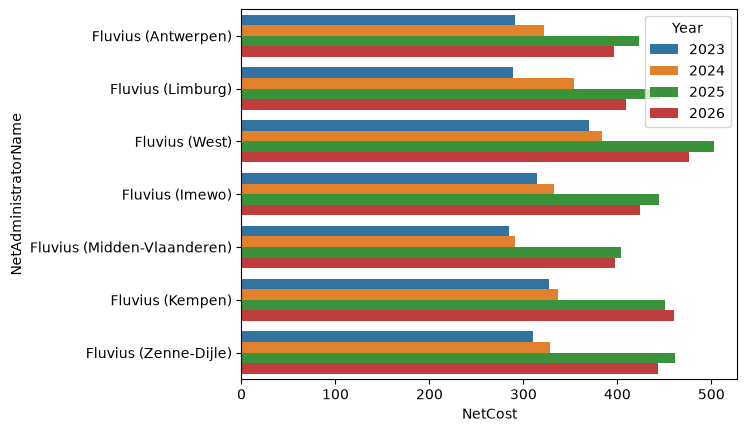

In [16]:
sns.barplot(data=factDistributionCost, x='NetCost', y='NetAdministratorName', hue='Year')
plt.show()


We voegen nu het percentage verschil toe tussen 2025 en 2023 per netbeheerder. We sorteren de dataframe eerst op basis van netbeheerder en jaartal. Dan voegen we op elke rij waar het jaar 2025 het percentageverschil toe. het percentageverschil wordt berekend door het verschil van de netkosten met de netkosten van de 2de vorige rij (de kosten van die netbeheerder in 2023) te delen door de netkosten van de 2de vorige rij (van 2023). Dan voegen we nog een % erachteraan stellen we het percentageverschil in de andere rijen in op '', zodat de cel leeg is.


In [17]:
factDistributionCost = factDistributionCost.sort_values(by=['NetAdministratorName', 'Year'])
factDistributionCost.loc[factDistributionCost['Year'] == '2025', 'Difference2023vs2025'] = factDistributionCost['NetCost'].diff(2) / factDistributionCost['NetCost'].shift(2)
factDistributionCost['Difference2023vs2025'] = (factDistributionCost['Difference2023vs2025'] * 100).round(2).astype(str) + '%'
factDistributionCost.replace('nan%', '', inplace=True)
factDistributionCost


,Year,NetAdministratorName,NetCost,Difference2023vs2025
0,2023,Fluvius (Antwerpen),291.090990,
10,2024,Fluvius (Antwerpen),321.702510,
20,2025,Fluvius (Antwerpen),422.678880,45.21%
28,2026,Fluvius (Antwerpen),396.836654,
4,2023,Fluvius (Imewo),314.388482,
14,2024,Fluvius (Imewo),332.200078,
22,2025,Fluvius (Imewo),444.277478,41.31%
30,2026,Fluvius (Imewo),423.794760,
6,2023,Fluvius (Kempen),327.585450,
16,2024,Fluvius (Kempen),337.153514,


# Opdracht 4


Eerst halen we het maandelijks verbruik op. We halen daarbij de kolommen `UserKey`, `Year`, `Month`, `MonthlyPeak` en `StartDateKey` op. De kolom `MonthlyPeak` bevat al het aangepast piekvermogen.


In [18]:
factEnergyUsageMonthly = pd.read_sql('SELECT UserKey, Year, Month, MonthlyPeak_kW, StartDateKey FROM FactEnergyUsageMonthly ORDER BY UserKey, Year, CAST(Month AS int)', connection)
factEnergyUsageMonthly['StartDateKey'] = pd.to_datetime(factEnergyUsageMonthly['StartDateKey'], format='%Y%m%d')
factEnergyUsageMonthly.head()


,UserKey,Year,Month,MonthlyPeak_kW,StartDateKey
0,1,2024,1,5.192,2024-01-01
1,1,2024,2,5.636,2024-02-01
2,1,2024,3,5.352,2024-03-01
3,1,2024,4,4.204,2024-04-01
4,1,2024,5,4.000,2024-05-01


We voegen per rij het aantal dagen in die maand toe als extra kolom.


In [19]:
factEnergyUsageMonthly['AantalDagen'] = factEnergyUsageMonthly['StartDateKey'].dt.days_in_month
factEnergyUsageMonthly.head()


,UserKey,Year,Month,MonthlyPeak_kW,StartDateKey,AantalDagen
0,1,2024,1,5.192,2024-01-01,31
1,1,2024,2,5.636,2024-02-01,29
2,1,2024,3,5.352,2024-03-01,31
3,1,2024,4,4.204,2024-04-01,30
4,1,2024,5,4.000,2024-05-01,31


We voegen de kolom `AantalDagen * MonthlyPeak_kW` toe door de kolom `AantalDagen` te vermenigvuldigen met de kolom `MonthlyPeak_kW`.


In [20]:
factEnergyUsageMonthly['AantalDagen * MonthlyPeak_kW'] = factEnergyUsageMonthly['AantalDagen'] * factEnergyUsageMonthly['MonthlyPeak_kW']
factEnergyUsageMonthly.head()


,UserKey,Year,Month,MonthlyPeak_kW,StartDateKey,AantalDagen,AantalDagen * MonthlyPeak_kW
0,1,2024,1,5.192,2024-01-01,31,160.952
1,1,2024,2,5.636,2024-02-01,29,163.444
2,1,2024,3,5.352,2024-03-01,31,165.912
3,1,2024,4,4.204,2024-04-01,30,126.120
4,1,2024,5,4.000,2024-05-01,31,124.000


We voegen de kolom `Cumulatieve som van (AantalDagen * MonthlyPeak_kW)` toe door de som van de afgelopen 12 maanden te nemen per gebruiker.


In [21]:
factEnergyUsageMonthly['Cumulatieve som van (AantalDagen * MonthlyPeak_kW)'] = factEnergyUsageMonthly.groupby('UserKey')['AantalDagen * MonthlyPeak_kW'].rolling(window=12, min_periods=1).sum().values
factEnergyUsageMonthly.head()


,UserKey,Year,Month,MonthlyPeak_kW,StartDateKey,AantalDagen,AantalDagen * MonthlyPeak_kW,Cumulatieve som van (AantalDagen * MonthlyPeak_kW)
0,1,2024,1,5.192,2024-01-01,31,160.952,160.952
1,1,2024,2,5.636,2024-02-01,29,163.444,324.396
2,1,2024,3,5.352,2024-03-01,31,165.912,490.308
3,1,2024,4,4.204,2024-04-01,30,126.120,616.428
4,1,2024,5,4.000,2024-05-01,31,124.000,740.428


We voegen de kolom `Cumulatieve som van (AantalDagen)` toe door de som van het aantal dagen in de afgelopen 12 maanden te nemen per gebruiker.


In [22]:
factEnergyUsageMonthly['Cumulatieve som van (AantalDagen)'] = factEnergyUsageMonthly.groupby('UserKey')['AantalDagen'].rolling(window=12, min_periods=1).sum().values
factEnergyUsageMonthly.head()


,UserKey,Year,Month,MonthlyPeak_kW,StartDateKey,AantalDagen,AantalDagen * MonthlyPeak_kW,Cumulatieve som van (AantalDagen * MonthlyPeak_kW),Cumulatieve som van (AantalDagen)
0,1,2024,1,5.192,2024-01-01,31,160.952,160.952,31.0
1,1,2024,2,5.636,2024-02-01,29,163.444,324.396,60.0
2,1,2024,3,5.352,2024-03-01,31,165.912,490.308,91.0
3,1,2024,4,4.204,2024-04-01,30,126.120,616.428,121.0
4,1,2024,5,4.000,2024-05-01,31,124.000,740.428,152.0


We voegen de gemiddelde maandpiek toe door de cumulatieve som van (AantalDagen \* MonthlyPeak_kW) te delen door de cumulatieve som van (AantalDagen).


In [23]:
factEnergyUsageMonthly['Gemiddelde maandpiek'] = factEnergyUsageMonthly['Cumulatieve som van (AantalDagen * MonthlyPeak_kW)'] / factEnergyUsageMonthly['Cumulatieve som van (AantalDagen)']
factEnergyUsageMonthly.head()


,UserKey,Year,Month,MonthlyPeak_kW,StartDateKey,AantalDagen,AantalDagen * MonthlyPeak_kW,Cumulatieve som van (AantalDagen * MonthlyPeak_kW),Cumulatieve som van (AantalDagen),Gemiddelde maandpiek
0,1,2024,1,5.192,2024-01-01,31,160.952,160.952,31.0,5.192000
1,1,2024,2,5.636,2024-02-01,29,163.444,324.396,60.0,5.406600
2,1,2024,3,5.352,2024-03-01,31,165.912,490.308,91.0,5.388000
3,1,2024,4,4.204,2024-04-01,30,126.120,616.428,121.0,5.094446
4,1,2024,5,4.000,2024-05-01,31,124.000,740.428,152.0,4.871237


We berekenen de factuurpiek door de gemiddelde maandpiek van de afgelopen 12 maanden te nemen per gebruiker.


In [24]:
factEnergyUsageMonthly['InvoicePeak'] = factEnergyUsageMonthly.groupby('UserKey')['Gemiddelde maandpiek'].rolling(window=12, min_periods=1).mean().values
factEnergyUsageMonthly.head()


,UserKey,Year,Month,MonthlyPeak_kW,StartDateKey,AantalDagen,AantalDagen * MonthlyPeak_kW,Cumulatieve som van (AantalDagen * MonthlyPeak_kW),Cumulatieve som van (AantalDagen),Gemiddelde maandpiek,InvoicePeak
0,1,2024,1,5.192,2024-01-01,31,160.952,160.952,31.0,5.192000,5.192000
1,1,2024,2,5.636,2024-02-01,29,163.444,324.396,60.0,5.406600,5.299300
2,1,2024,3,5.352,2024-03-01,31,165.912,490.308,91.0,5.388000,5.328867
3,1,2024,4,4.204,2024-04-01,30,126.120,616.428,121.0,5.094446,5.270262
4,1,2024,5,4.000,2024-05-01,31,124.000,740.428,152.0,4.871237,5.190457


We nemen specifiek de kolommen `UserKey`, `Year`, `Month` en `InvoicePeak` van de dataframe voor een beter overzicht.


In [25]:
factEnergyUsageMonthly = factEnergyUsageMonthly[['UserKey', 'Year', 'Month', 'InvoicePeak']]
factEnergyUsageMonthly.head()


,UserKey,Year,Month,InvoicePeak
0,1,2024,1,5.192000
1,1,2024,2,5.299300
2,1,2024,3,5.328867
3,1,2024,4,5.270262
4,1,2024,5,5.190457


We schrijven nu een functie die automatisch de kolom toevoegd aan de dataframe.


In [26]:
def calculate_invoice_peak(df):
    df['StartDateKey'] = pd.to_datetime(df['StartDateKey'], format='%Y%m%d')
    df['AantalDagen'] = df['StartDateKey'].dt.days_in_month
    df['AantalDagen * MonthlyPeak_kW'] = df['AantalDagen'] * df['MonthlyPeak_kW']
    df['Cumulatieve som van (AantalDagen * MonthlyPeak_kW)'] = df.groupby('UserKey')['AantalDagen * MonthlyPeak_kW'].rolling(window=12, min_periods=1).sum().values
    df['Cumulatieve som van (AantalDagen)'] = df.groupby('UserKey')['AantalDagen'].rolling(window=12, min_periods=1).sum().values
    df['Gemiddelde maandpiek'] = df['Cumulatieve som van (AantalDagen * MonthlyPeak_kW)'] / df['Cumulatieve som van (AantalDagen)']
    df['InvoicePeak'] = df.groupby('UserKey')['Gemiddelde maandpiek'].rolling(window=12, min_periods=1).mean().values
    df.drop(columns=['AantalDagen', 'AantalDagen * MonthlyPeak_kW', 'Cumulatieve som van (AantalDagen * MonthlyPeak_kW)', 'Cumulatieve som van (AantalDagen)', 'Gemiddelde maandpiek'], inplace=True) 
    return


We lezen de data van gebruiker 1303 in en transformeren de dataframe zodat de kolommen overeenkomen met de data uit onze database.


In [27]:
energyUsageMonthlyUser1303 = pd.read_csv('../data/Historiek_piekvermogen_elektriciteit_1303.csv', sep=';')
energyUsageMonthlyUser1303['UserKey'] = 1303
energyUsageMonthlyUser1303['Van (datum)'] = pd.to_datetime(energyUsageMonthlyUser1303['Van (datum)'], format='%d-%m-%Y')
energyUsageMonthlyUser1303['Year'] = energyUsageMonthlyUser1303['Van (datum)'].dt.year.astype(str)
energyUsageMonthlyUser1303['Month'] = energyUsageMonthlyUser1303['Van (datum)'].dt.month.astype(str)
energyUsageMonthlyUser1303['MonthlyPeak_kW'] = energyUsageMonthlyUser1303['Volume'].str.replace(',', '.').astype(float)
energyUsageMonthlyUser1303['StartDateKey'] = energyUsageMonthlyUser1303['Van (datum)'].dt.strftime('%Y%m%d').astype(int)
energyUsageMonthlyUser1303 = energyUsageMonthlyUser1303[['UserKey', 'Year', 'Month', 'MonthlyPeak_kW', 'StartDateKey']]
energyUsageMonthlyUser1303.head()


,UserKey,Year,Month,MonthlyPeak_kW,StartDateKey
0,1303,2021,9,3.816,20210901
1,1303,2021,10,5.387,20211001
2,1303,2021,11,7.637,20211101
3,1303,2021,12,6.783,20211201
4,1303,2022,1,6.100,20220101


We testen nu de functie uit.


In [28]:
calculate_invoice_peak(energyUsageMonthlyUser1303)
energyUsageMonthlyUser1303 = energyUsageMonthlyUser1303[['UserKey', 'Year', 'Month', 'InvoicePeak']]
energyUsageMonthlyUser1303.head()


,UserKey,Year,Month,InvoicePeak
0,1303,2021,9,3.816000
1,1303,2021,10,4.215189
2,1303,2021,11,4.680408
3,1303,2021,12,4.987478
4,1303,2022,1,5.179473


We zoeken de factuurpiek van de gebruiker 1303 voor april en mei 2024.


In [29]:
energyUsageMonthlyUser1303[(energyUsageMonthlyUser1303['Year'] == '2024') & (energyUsageMonthlyUser1303['Month'].isin(['4', '5']))]


,UserKey,Year,Month,InvoicePeak
31,1303,2024,4,12.881020
32,1303,2024,5,12.880878
